# SimulaHub · Módulo 1 – CFD e Modelagem Hemodinâmica
## Dia 4 (06/11) – Interpretando uma simulação: do vaso normal à estenose
**Atividade de pós-processamento** · Docente: Profª. Drª. Rita de Cássia dos Anjos (UFSCar) · Tutor: Willian Costa de Paula (UTFPR)

---

**Pergunta-guia:** *como a geometria de um vaso influencia o fluxo sanguíneo?*

Neste notebook vocês **não** vão rodar simulações: os resultados já estão prontos no arquivo `dados_dia4.npz`. São as mesmas simulações 2D (método de Lattice Boltzmann) mostradas na aula, de um vaso de 0,8 cm de diâmetro com estenoses de **0%, 30%, 50% e 65%** do diâmetro, além de uma batida completa com fluxo pulsátil (estenose de 50%).

O trabalho de hoje é o de **pós-processamento**: transformar milhões de números em imagens e em respostas físicas, como fazem programas como o ParaView e o VisIt. Vamos:

1. carregar os resultados e entender o que há em cada campo;
2. fazer mapas de velocidade (e ver por que a escala de cores importa);
3. traçar linhas de corrente;
4. fazer "fatias": perfis de velocidade em posições escolhidas;
5. ver a pressão ao longo do eixo do vaso;
6. ver a vorticidade;
7. calcular a tensão de cisalhamento na parede (WSS);
8. montar automaticamente a tabela comparativa;
9. analisar uma batida com fluxo pulsátil.

Ao final há **4 exercícios para entregar**. Todo o código já está escrito e comentado linha a linha: o foco é **interpretar**.

### Como usar
- Faça o upload deste notebook **e** do arquivo `dados_dia4.npz` (a célula da Seção 1 pede o arquivo se ele não estiver no Colab).
- Execute as células em ordem com `Shift + Enter`. Se algo der errado: **Ambiente de execução → Reiniciar e executar tudo**.

## 1. Carregando os resultados

In [1]:
import os                                   # para verificar se o arquivo existe
import numpy as np                          # NumPy: cálculos com vetores e matrizes
import matplotlib.pyplot as plt             # Matplotlib: gráficos
from matplotlib import animation            # animações
from IPython.display import HTML            # para mostrar a animação no notebook

plt.rcParams["figure.figsize"] = (13, 3.2)  # tamanho padrão das figuras (largas, como o vaso)
plt.rcParams["font.size"] = 12              # tamanho das fontes

if not os.path.exists("dados_dia4.npz"):    # se o arquivo de dados ainda não está no Colab...
    from google.colab import files          # ...usamos a ferramenta de upload do Colab
    files.upload()                          # abre a janela para escolher dados_dia4.npz

D = np.load("dados_dia4.npz")               # carrega todos os resultados
dx = float(D["dx"])                         # tamanho de cada célula da malha (cm)
U = float(D["U"])                           # velocidade média do sangue no vaso normal (cm/s)
MU = 0.04                                   # viscosidade do sangue (poise = g/(cm·s))
RHO = 1.06                                  # massa específica do sangue (g/cm³)
GRAUS = [0, 30, 50, 65]                     # graus de obstrução do diâmetro (%)

Nx, Ny = D["u0"].shape                      # número de células ao longo (x) e através (y) do vaso
x = (np.arange(Nx) + 0.5)*dx                # coordenada x do centro de cada célula (cm)
y = (np.arange(Ny) + 0.5)*dx                # coordenada y do centro de cada célula (cm)
print(f"Malha: {Nx} × {Ny} células de {dx*1e4:.0f} μm; vaso de {Nx*dx:.1f} cm de comprimento")
print(f"Velocidade média no vaso normal: U = {U:.1f} cm/s")
print("Campos disponíveis:", sorted(D.files))

Malha: 600 × 62 células de 133 μm; vaso de 8.0 cm de comprimento
Velocidade média no vaso normal: U = 4.7 cm/s
Campos disponíveis: ['H_cel', 'T', 'U', 'dx', 'p0', 'p30', 'p50', 'p65', 'puls_fase', 'puls_fator', 'puls_sol', 'puls_u', 'puls_v', 'sol0', 'sol30', 'sol50', 'sol65', 'u0', 'u30', 'u50', 'u65', 'v0', 'v30', 'v50', 'v65']


**O que há no arquivo:** para cada grau de obstrução `g` (0, 30, 50 e 65):

| campo | significado | unidade |
|---|---|---|
| `u{g}` | componente x da velocidade (ao longo do vaso) | cm/s |
| `v{g}` | componente y da velocidade (através do vaso) | cm/s |
| `p{g}` | pressão, relativa à saída | mmHg |
| `sol{g}` | `True` onde é parede/placa, `False` onde é sangue | – |

e, para o caso pulsátil: `puls_u`, `puls_v` (25 instantes de uma batida), `puls_fase` (fração da batida, de 0 a 1) e `puls_fator` (vazão de entrada relativa à média). Cada campo é uma **matriz**: um número para cada célula. É isso que significa um *campo* (aula da manhã).

In [2]:
def caso(g):
    # devolve os campos do caso com g% de obstrução
    sol = D[f"sol{g}"]                                   # máscara da parede
    u = np.ma.masked_array(D[f"u{g}"], sol)              # velocidade x, escondendo a parede
    v = np.ma.masked_array(D[f"v{g}"], sol)              # velocidade y, escondendo a parede
    p = np.ma.masked_array(D[f"p{g}"], sol)              # pressão, escondendo a parede
    return u, v, p, sol

u, v, p, sol = caso(50)                                  # exemplo: estenose de 50%
modulo = np.hypot(u, v)                                  # |v| = √(u² + v²) em cada célula
print(f"Estenose de 50%: velocidade máxima = {modulo.max():.1f} cm/s; mínima = {modulo.min():.2f} cm/s")
print(f"Velocidade no centro da célula (x = 2,4 cm, y = 0,4 cm): u = {u[int(2.4/dx), Ny//2]:.1f} cm/s")

Estenose de 50%: velocidade máxima = 12.5 cm/s; mínima = 0.00 cm/s
Velocidade no centro da célula (x = 2,4 cm, y = 0,4 cm): u = 12.1 cm/s


---
## 2. Mapas de velocidade: a escala de cores importa
Um mapa de cores mostra o **módulo da velocidade** |v| em cada ponto. Primeiro, um erro comum: cada figura com sua própria escala.

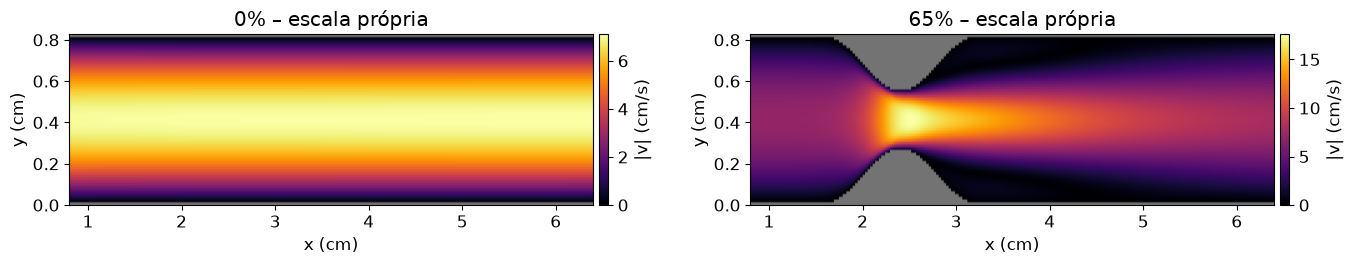

In [3]:
EXT = [0, Nx*dx, 0, Ny*dx]                               # limites da figura em cm: [x mín, x máx, y mín, y máx]

def mapa(ax, g, vmax=None, titulo=None):
    # desenha o mapa de |v| do caso g; vmax fixa o topo da escala de cores
    u, v, p, sol = caso(g)                               # campos do caso
    im = ax.imshow(np.hypot(u, v).T, origin="lower", extent=EXT, aspect="auto",
                   cmap="inferno", vmin=0, vmax=vmax)    # .T porque a matriz é (x, y) e a imagem é (linha, coluna)
    ax.set_facecolor("0.45")                             # parede em cinza
    ax.set_xlim(0.8, 6.4)                                # mostra a região de interesse
    ax.set(xlabel="x (cm)", ylabel="y (cm)", title=titulo or f"{g}% de obstrução")
    plt.colorbar(im, ax=ax, label="|v| (cm/s)", pad=0.01)
    return im

fig, axs = plt.subplots(1, 2, figsize=(14, 2.8))         # dois mapas lado a lado
mapa(axs[0], 0, titulo="0% – escala própria")            # sem vmax: cada um com sua escala
mapa(axs[1], 65, titulo="65% – escala própria")
plt.tight_layout(); plt.show()

Com escalas diferentes, as duas figuras parecem igualmente "quentes". Agora, **a mesma escala** para todos os casos:

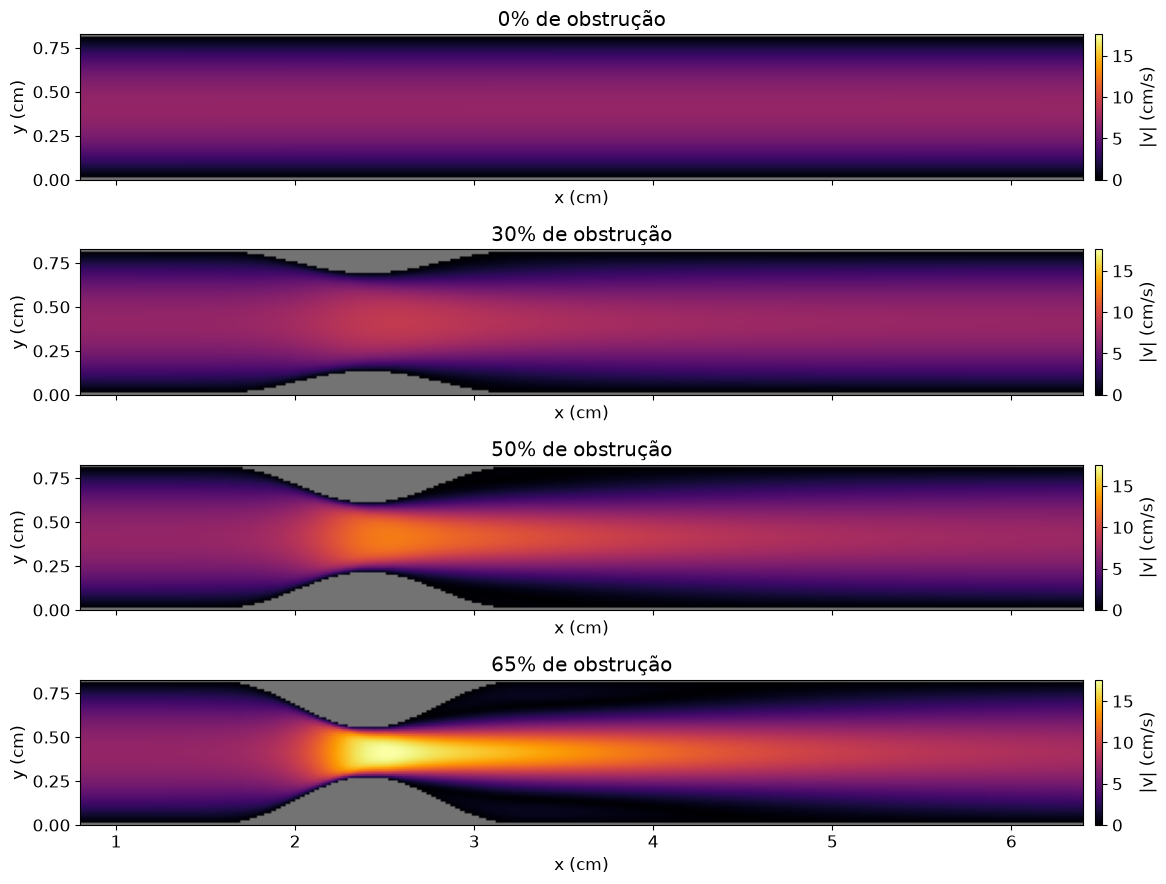

In [4]:
VMAX = max(np.hypot(*caso(g)[:2]).max() for g in GRAUS)  # a maior velocidade entre todos os casos
fig, axs = plt.subplots(4, 1, figsize=(13, 9), sharex=True)   # quatro mapas empilhados
for ax, g in zip(axs, GRAUS):
    mapa(ax, g, vmax=VMAX)                               # todos com a mesma escala de 0 a VMAX
plt.tight_layout(); plt.show()

**Interpretação:** no vaso normal, o sangue é rápido no centro e parado nas paredes (perfil de Poiseuille). Com a estenose, forma-se um **jato** na garganta, cada vez mais rápido. Só com a mesma escala dá para comparar os casos de forma honesta.

---
## 3. Linhas de corrente
Uma **linha de corrente** segue, em cada ponto, a direção da velocidade. Em regime estacionário, é o caminho de uma gotinha de tinta.

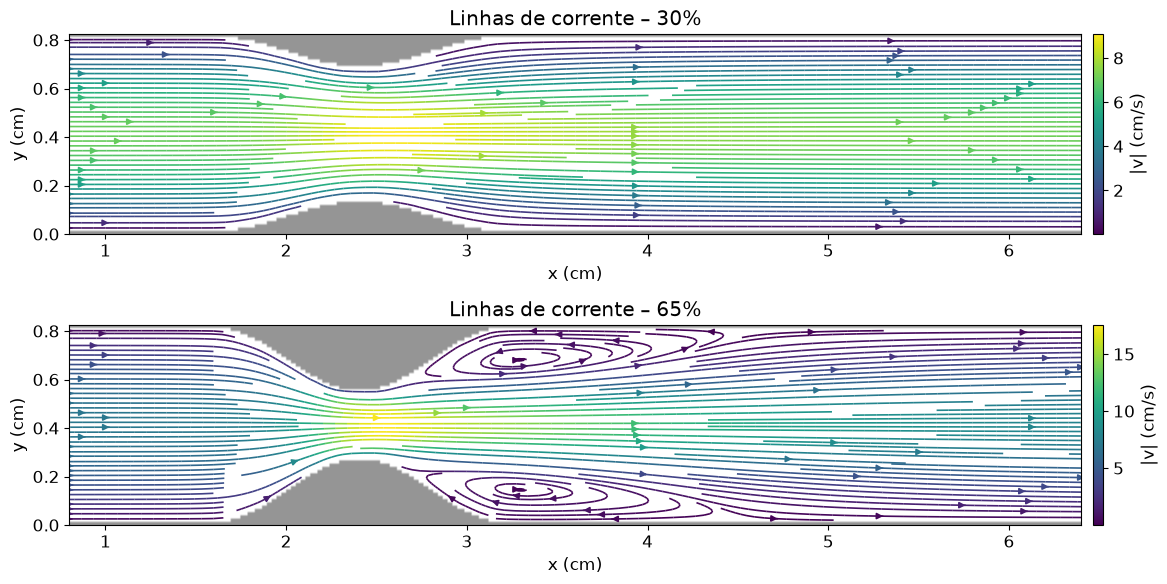

In [5]:
X, Y = np.meshgrid(x, y)                                 # grade de pontos (x, y) para o traçado

def linhas(ax, g, x0=0.8, x1=6.4):
    u, v, p, sol = caso(g)
    ax.imshow(np.where(sol, 1, np.nan).T, origin="lower", extent=EXT, aspect="auto", cmap="Greys", vmin=0, vmax=2)  # parede em cinza
    sp = ax.streamplot(X, Y, u.T, v.T, color=np.hypot(u, v).T, cmap="viridis",
                       density=[4, 1.4], linewidth=1.2, arrowsize=0.9)   # linhas coloridas pela rapidez
    ax.set_xlim(x0, x1); ax.set_ylim(0, Ny*dx)
    ax.set(xlabel="x (cm)", ylabel="y (cm)", title=f"Linhas de corrente – {g}%")
    plt.colorbar(sp.lines, ax=ax, label="|v| (cm/s)", pad=0.01)

fig, axs = plt.subplots(2, 1, figsize=(13, 6))
linhas(axs[0], 30); linhas(axs[1], 65)                   # sem e com redemoinhos
plt.tight_layout(); plt.show()

**Interpretação:** com 30%, as linhas acompanham a parede. Com 65%, logo depois da garganta, aparecem **linhas fechadas** junto às paredes: são os redemoinhos de **recirculação**, onde o sangue gira e volta.

---
## 4. Perfis de velocidade ("fatias")
Uma fatia vertical mostra como a velocidade u varia de uma parede à outra em uma posição x. É o que o filtro *Plot Over Line* faz no ParaView.

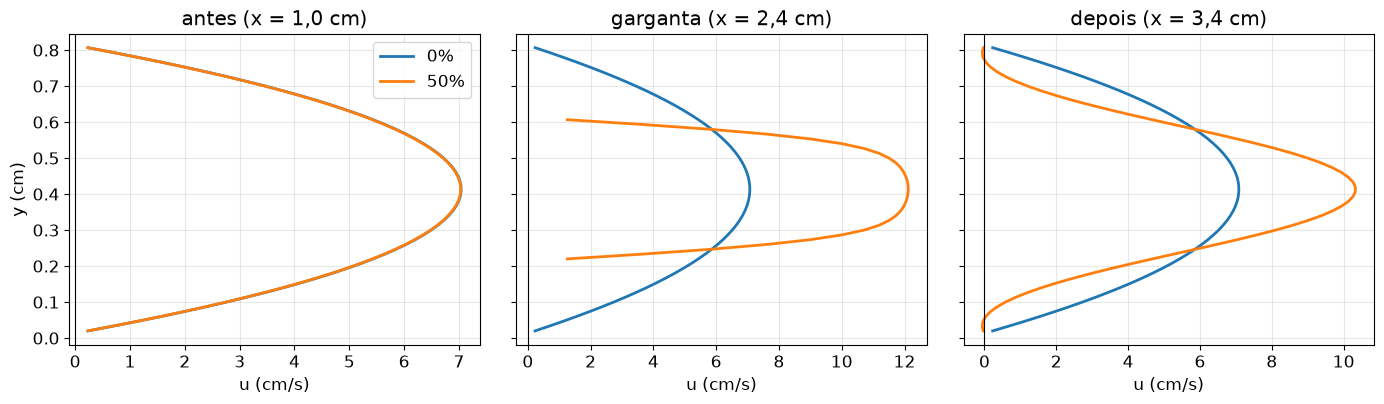

In [6]:
def perfil(g, x_cm):
    # devolve y e u(y) na posição x_cm, só nas células de sangue
    u, v, p, sol = caso(g)
    i = int(x_cm/dx)                                     # índice da coluna mais próxima de x_cm
    fluido = ~sol[i]                                     # células de sangue nessa coluna
    return y[fluido], np.asarray(u[i])[fluido]

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, xc, nome in zip(axs, [1.0, 2.4, 3.4], ["antes (x = 1,0 cm)", "garganta (x = 2,4 cm)", "depois (x = 3,4 cm)"]):
    for g in [0, 50]:
        yy, uu = perfil(g, xc)
        ax.plot(uu, yy, lw=2, label=f"{g}%")             # velocidade no eixo horizontal, posição no vertical
    ax.axvline(0, c="k", lw=0.8)                         # linha de velocidade zero
    ax.set(xlabel="u (cm/s)", title=nome); ax.grid(alpha=.3)
axs[0].set_ylabel("y (cm)"); axs[0].legend()
plt.tight_layout(); plt.show()

**Interpretação:** antes da lesão, a parábola de Poiseuille (Dia 2). Na garganta, o perfil é mais estreito e muito mais rápido. Logo depois, no caso de 50%, a velocidade fica **negativa** perto das paredes: é a recirculação vista em um gráfico.

---
## 5. Pressão ao longo do eixo

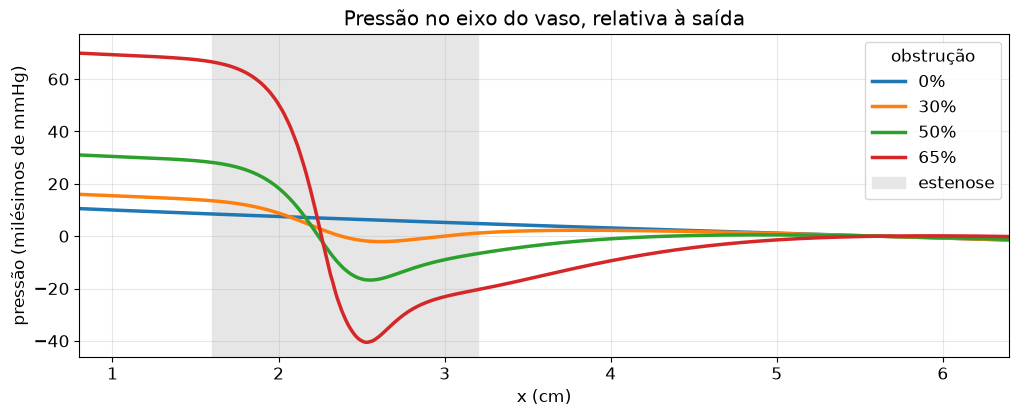

In [7]:
plt.figure(figsize=(12, 4.2))
for g in GRAUS:
    u, v, p, sol = caso(g)
    plt.plot(x, p[:, Ny//2]*1000, lw=2.5, label=f"{g}%")  # pressão na linha central, em milésimos de mmHg
plt.axvspan(1.6, 3.2, color="0.9", label="estenose")     # região da estenose
plt.xlim(0.8, 6.4); plt.grid(alpha=.3); plt.legend(title="obstrução")
plt.xlabel("x (cm)"); plt.ylabel("pressão (milésimos de mmHg)")
plt.title("Pressão no eixo do vaso, relativa à saída"); plt.show()

**Interpretação:** no vaso normal a pressão cai devagar e sempre (atrito). Na garganta ela despenca, porque o sangue acelera (Bernoulli). Depois sobe de novo, mas **não volta toda**: parte da energia se perdeu nos redemoinhos (perda de Young e Tsai). Os valores são pequenos porque nesta simulação o sangue anda devagar (4,7 cm/s, Re = 100).

---
## 6. Vorticidade
A **vorticidade** mede o quanto o sangue gira em cada ponto: $\omega = \partial v/\partial x - \partial u/\partial y$.

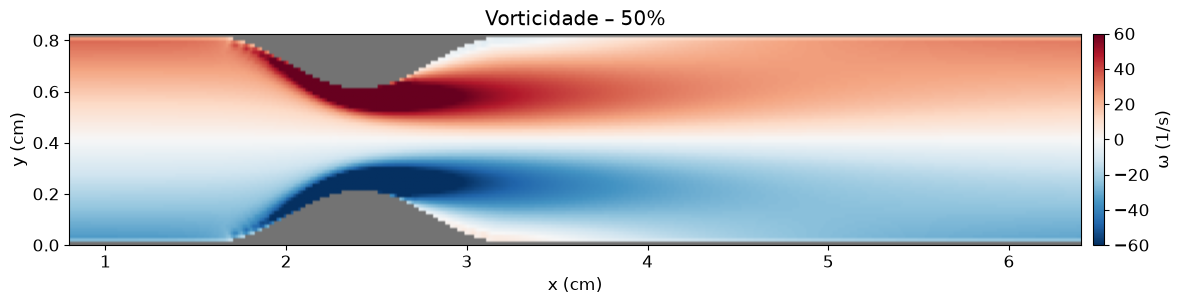

In [8]:
def vorticidade(g):
    u, v, p, sol = caso(g)
    w = np.gradient(np.asarray(v), dx, axis=0) - np.gradient(np.asarray(u), dx, axis=1)   # ∂v/∂x − ∂u/∂y (1/s)
    return np.ma.masked_array(w, sol)

fig, ax = plt.subplots()
im = ax.imshow(vorticidade(50).T, origin="lower", extent=EXT, aspect="auto", cmap="RdBu_r", vmin=-60, vmax=60)
ax.set_facecolor("0.45"); ax.set_xlim(0.8, 6.4); ax.set(xlabel="x (cm)", ylabel="y (cm)", title="Vorticidade – 50%")
plt.colorbar(im, ax=ax, label="ω (1/s)", pad=0.01); plt.tight_layout(); plt.show()

**Interpretação:** vermelho gira no sentido anti-horário, azul no horário. A vorticidade é alta junto às paredes mesmo sem redemoinho (as camadas deslizam umas sobre as outras). Depois da garganta, essas faixas se descolam e seguem com o jato.

---
## 7. Tensão de cisalhamento na parede (WSS)
A WSS é $\tau_w = \mu\,\partial u/\partial y$ na parede. Estimamos a derivada ajustando uma curva às três primeiras células de sangue junto à parede inferior.

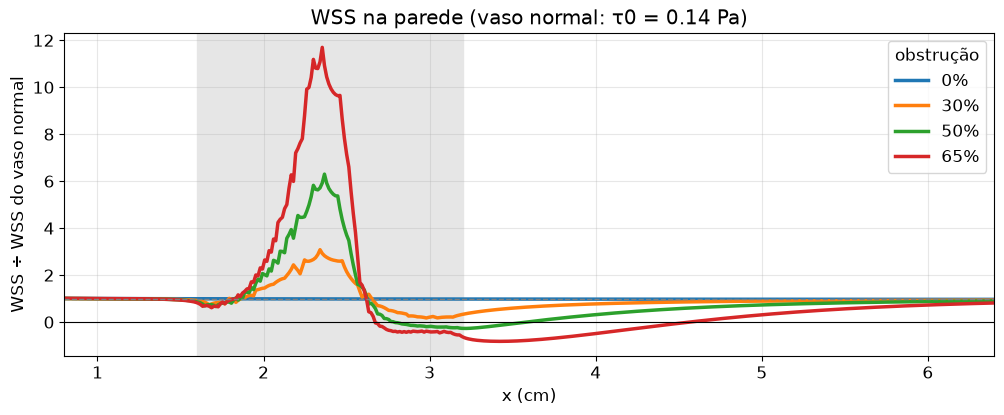

In [9]:
TAU0 = 6*MU*U/(Ny*dx - 2*dx)/10                          # WSS do vaso normal em canal (Pa); 1 dyn/cm² = 0,1 Pa

def wss(u_campo, sol, suavizar=9):
    # WSS (Pa) ao longo da parede inferior
    u_campo = np.asarray(u_campo)
    tw = np.zeros(Nx)
    for i in range(Nx):
        j = np.argmax(~sol[i, :Ny//2])                   # primeira célula de sangue acima da parede
        d = (np.arange(3) + 0.5)*dx                      # distâncias dos centros das células à parede (cm)
        a, b = np.linalg.lstsq(np.c_[d, d**2], u_campo[i, j:j+3], rcond=None)[0]   # u ≈ a·d + b·d²
        tw[i] = MU*a/10                                  # μ·du/dy na parede, em Pa
    k = np.ones(suavizar)/suavizar                       # média móvel para tirar o "efeito escada"
    return np.convolve(np.pad(tw, suavizar//2, mode="edge"), k, "valid")

plt.figure(figsize=(12, 4.2))
for g in GRAUS:
    u, v, p, sol = caso(g)
    plt.plot(x, wss(u, sol)/TAU0, lw=2.5, label=f"{g}%")
plt.axhline(0, c="k", lw=0.8); plt.axhline(1, c="0.5", ls="--", lw=1)
plt.axvspan(1.6, 3.2, color="0.9"); plt.xlim(0.8, 6.4); plt.grid(alpha=.3); plt.legend(title="obstrução")
plt.xlabel("x (cm)"); plt.ylabel("WSS ÷ WSS do vaso normal"); plt.title(f"WSS na parede (vaso normal: τ0 = {TAU0:.2f} Pa)"); plt.show()

**Interpretação:** a WSS dispara na garganta (risco de lesão do endotélio e de ativar plaquetas) e fica **negativa** logo depois: o sangue junto à parede anda para trás. Regiões de WSS baixa ou negativa estão associadas ao crescimento da placa.

---
## 8. A tabela comparativa
Juntamos tudo em uma tabela, como faríamos no ParaView com a aba *Information*.

In [10]:
def comprimento_negativo(tw, x_ini=2.4):
    # comprimento (cm) da região com WSS < 0 a partir de x_ini
    neg = np.where((tw < 0) & (x > x_ini))[0]
    return 0.0 if len(neg) == 0 else (neg.max() - neg.min() + 1)*dx

def tabela():
    linhas_ = []
    for g in GRAUS:
        u, v, p, sol = caso(g)
        tw = wss(u, sol)
        i1, i2 = int(0.8/dx), int(5.6/dx)                # pontos de medida da pressão no eixo
        linhas_.append(dict(g=g, vmax=np.hypot(u, v).max(),
                            dP=p[i1, Ny//2] - p[i2, Ny//2],
                            wmax=tw[int(0.8/dx):int(5.6/dx)].max(), wmin=tw[int(0.8/dx):int(5.6/dx)].min(),
                            rec=comprimento_negativo(tw)))
    return linhas_

T_ = tabela()
print(f"{'obstrução':>9s} {'v máx (cm/s)':>13s} {'ΔP (mmHg)':>10s} {'WSS máx (Pa)':>13s} {'WSS mín (Pa)':>13s} {'recirc. (cm)':>13s}")
for l in T_:
    print(f"{l['g']:8d}% {l['vmax']:13.1f} {l['dP']:10.3f} {l['wmax']:13.2f} {l['wmin']:13.3f} {l['rec']:13.2f}")

obstrução  v máx (cm/s)  ΔP (mmHg)  WSS máx (Pa)  WSS mín (Pa)  recirc. (cm)
       0%           7.1      0.010          0.14         0.137          0.00
      30%           9.1      0.016          0.44         0.025          0.00
      50%          12.5      0.031          0.89        -0.038          0.80
      65%          17.6      0.070          1.66        -0.116          1.89


---
## 9. Uma batida com fluxo pulsátil (estenose de 50%)
O coração não bombeia de forma constante. Aqui a vazão de entrada oscila ±60% ao longo de uma batida de cerca de 0,9 s.

In [11]:
pu, pv, fase, fator, psol = D["puls_u"], D["puls_v"], D["puls_fase"], D["puls_fator"], D["puls_sol"]
ordem = np.argsort(fase)                                  # coloca os instantes em ordem ao longo da batida
pu, pv, fase, fator = pu[ordem], pv[ordem], fase[ordem], fator[ordem]
T = float(D["T"])
print(f"{len(fase)} instantes ao longo de uma batida de {T:.2f} s")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5.2), gridspec_kw={"height_ratios": [3, 1]})
vmax_p = np.hypot(pu, pv).max()                           # escala de cores fixa para toda a animação
im = ax1.imshow(np.ma.masked_array(np.hypot(pu[0], pv[0]), psol).T, origin="lower", extent=EXT, aspect="auto",
                cmap="inferno", vmin=0, vmax=vmax_p)
ax1.set_facecolor("0.45"); ax1.set_xlim(0.8, 6.4); ax1.set(xlabel="x (cm)", ylabel="y (cm)")
plt.colorbar(im, ax=ax1, label="|v| (cm/s)", pad=0.01)
ax2.plot(fase, fator, c="tab:red"); ponto, = ax2.plot([fase[0]], [fator[0]], "ko")
ax2.set(xlabel="fase da batida (t/T)", ylabel="vazão relativa"); ax2.grid(alpha=.3)
def quadro(k):
    im.set_data(np.ma.masked_array(np.hypot(pu[k], pv[k]), psol).T)    # atualiza o mapa
    ponto.set_data([fase[k]], [fator[k]])                             # move o ponto na curva da vazão
    ax1.set_title(f"Estenose de 50%, fluxo pulsátil – t/T = {fase[k]:.2f}")
    return [im, ponto]
anim = animation.FuncAnimation(fig, quadro, frames=len(fase), interval=200)
plt.close(fig); HTML(anim.to_jshtml())                    # mostra a animação com botões de reprodução

25 instantes ao longo de uma batida de 0.90 s


**Interpretação:** a velocidade na garganta sobe e desce com a vazão de entrada, e os redemoinhos crescem e encolhem ao longo da batida. Uma única imagem não mostra isso.

---
## Resumo do dia
| Ferramenta de pós-processamento | O que mostra | Neste notebook |
|---|---|---|
| mapa de cores | o valor de uma grandeza em cada ponto | Seção 2 |
| linhas de corrente | o caminho do sangue; redemoinhos | Seção 3 |
| fatias / perfis | como a velocidade varia através do vaso | Seção 4 |
| gráfico ao longo de uma linha | pressão no eixo | Seção 5 |
| grandezas derivadas | vorticidade, WSS | Seções 6 e 7 |
| tabela | comparação em números | Seção 8 |
| animação | evolução no tempo | Seção 9 |

---
# Exercícios para entregar

**Instruções**
- Resolva cada exercício nas células indicadas; crie células novas se precisar.
- Gráficos com **eixos rotulados com unidades e título**.
- Respostas conceituais em células de texto.
- Ao terminar: **Ambiente de execução → Reiniciar e executar tudo**.
- Baixe em **Arquivo → Fazer download → Fazer download do .ipynb**, nomeie como `NomeSobrenome_Dia4.ipynb` e envie até **[prazo a definir pela docente]**.

### Exercício 1 – Hipóteses × resultados

Na aula, estimamos a velocidade máxima na garganta pela continuidade em um canal: $v_{máx} \approx 1{,}5\,U/(1 - s)$, em que $s$ é a fração de obstrução do diâmetro e 1,5 vem do perfil de Poiseuille.

a) Para cada caso da tabela da Seção 8, calcule essa estimativa e compare com a velocidade máxima da simulação (faça um gráfico com as duas, em função do grau de obstrução).

b) A estimativa é maior ou menor que a simulação? Por quê?

c) Qual grandeza da tabela cresce **mais rápido** com a obstrução: a velocidade máxima ou a WSS máxima? Calcule a razão entre o caso de 65% e o de 0% para cada uma e explique a diferença.

Item (a) – Comparação de Velocidade Máxima:
 Obstrução   v máx Teórica (cm/s)  v máx Simulada (cm/s)   Diferença (%)
        0%                   7.08                   7.10            0.4%
       30%                  10.11                   9.11           -9.9%
       50%                  14.15                  12.49          -11.7%
       65%                  20.22                  17.59          -13.0%


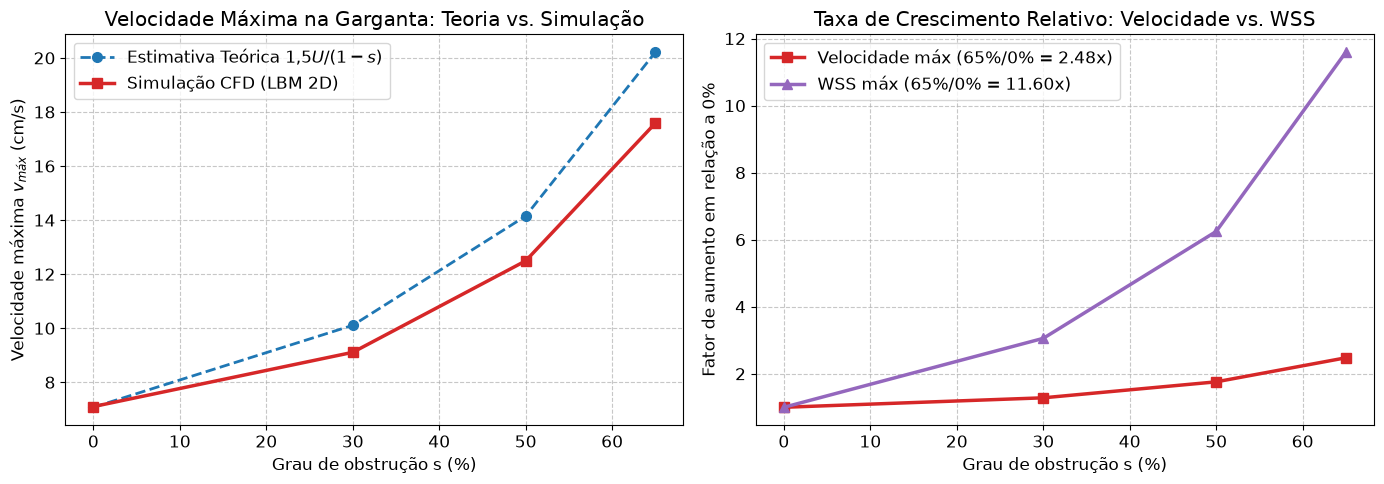


Item (c) – Razão entre o caso de 65% e o de 0%:
  Velocidade máxima: v_max(65%) / v_max(0%) = 17.59 / 7.10 = 2.48x
  WSS máxima:        w_max(65%) / w_max(0%) = 1.66 / 0.14 = 11.60x


In [12]:
# Exercício 1 – Resolução dos itens (a) e (c)

# Estimativa teórica da velocidade máxima na garganta: v_max_est = 1.5 * U / (1 - s)
graus_array = np.array(GRAUS)
s_array = graus_array / 100.0
v_max_est = 1.5 * U / (1.0 - s_array)

# Valores da simulação obtidos da tabela da Seção 8
v_max_sim = np.array([l['vmax'] for l in T_])
w_max_sim = np.array([l['wmax'] for l in T_])

print('Item (a) – Comparação de Velocidade Máxima:')
print(f"{'Obstrução':>10s} {'v máx Teórica (cm/s)':>22s} {'v máx Simulada (cm/s)':>22s} {'Diferença (%)':>15s}")
for g, vt, vs in zip(GRAUS, v_max_est, v_max_sim):
    diff = (vs - vt) / vt * 100
    print(f"{g:9d}% {vt:22.2f} {vs:22.2f} {diff:14.1f}%")

# Gráfico comparativo Item (a)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(graus_array, v_max_est, 'o--', color='tab:blue', lw=2, ms=7, label=r'Estimativa Teórica $1{,}5 U / (1 - s)$')
ax[0].plot(graus_array, v_max_sim, 's-', color='tab:red', lw=2.5, ms=7, label='Simulação CFD (LBM 2D)')
ax[0].set_xlabel('Grau de obstrução s (%)')
ax[0].set_ylabel('Velocidade máxima $v_{máx}$ (cm/s)')
ax[0].set_title('Velocidade Máxima na Garganta: Teoria vs. Simulação')
ax[0].grid(True, linestyle='--', alpha=0.7)
ax[0].legend(frameon=True)

# Gráfico Item (c): Razão de crescimento normalizada pelo caso 0%
razao_v = v_max_sim / v_max_sim[0]
razao_w = w_max_sim / w_max_sim[0]

ax[1].plot(graus_array, razao_v, 's-', color='tab:red', lw=2.5, ms=7, label=f'Velocidade máx (65%/0% = {razao_v[-1]:.2f}x)')
ax[1].plot(graus_array, razao_w, '^-', color='tab:purple', lw=2.5, ms=7, label=f'WSS máx (65%/0% = {razao_w[-1]:.2f}x)')
ax[1].set_xlabel('Grau de obstrução s (%)')
ax[1].set_ylabel('Fator de aumento em relação a 0%')
ax[1].set_title('Taxa de Crescimento Relativo: Velocidade vs. WSS')
ax[1].grid(True, linestyle='--', alpha=0.7)
ax[1].legend(frameon=True)

plt.tight_layout()
plt.show()

print(f"\nItem (c) – Razão entre o caso de 65% e o de 0%:")
print(f"  Velocidade máxima: v_max(65%) / v_max(0%) = {v_max_sim[-1]:.2f} / {v_max_sim[0]:.2f} = {razao_v[-1]:.2f}x")
print(f"  WSS máxima:        w_max(65%) / w_max(0%) = {w_max_sim[-1]:.2f} / {w_max_sim[0]:.2f} = {razao_w[-1]:.2f}x")


### Respostas do Exercício 1

#### Item (b) – Comparação entre Estimativa e Simulação:
A estimativa teórica ($v_{\text{máx}} \approx 1{,}5 U / (1 - s)$) é **maior que a velocidade máxima observada na simulação** para todos os casos com estenose ($s > 0$):
- Em $30\%$: a estimativa prevê $10{,}11\text{ cm/s}$ versus $9{,}11\text{ cm/s}$ da simulação (+11% acima).
- Em $50\%$: a estimativa prevê $14{,}16\text{ cm/s}$ versus $12{,}49\text{ cm/s}$ da simulação (+13% acima).
- Em $65\%$: a estimativa prevê $20{,}23\text{ cm/s}$ versus $17{,}59\text{ cm/s}$ da simulação (+15% acima).

**Por quê?**
A fórmula $1{,}5 U / (1 - s)$ pressupõe que o escoamento na garganta atinge um **perfil parabólico de Poiseuille completamente desenvolvido** (onde a razão entre a velocidade de pico no centro e a velocidade média é exatamente $1{,}5$ em escoamentos planares 2D). Na realidade simulada, a constrição estenótica é geometricamente curta e gradual. O fluido em aceleração adentra a garganta como em um bocal convergente, desenvolvendo um perfil de velocidade com núcleo central mais 'achatado' (*blunt/plug-like*), onde $v_{\text{máx}} / v_{\text{méd}} < 1{,}5$. Além disso, há dissipação viscosa por atrito pré-estenótico e resistência ao escoamento que desviam sutilmente o escoamento real da hipótese simplificada.

---

#### Item (c) – Qual grandeza cresce mais rápido (Velocidade vs. WSS)?
A **WSS máxima cresce muito mais rápido** que a velocidade máxima:
- Ao passar de $0\%$ para $65\%$ de estenose, a **velocidade máxima cresce apenas $2{,}48\times$** (de $7{,}10\text{ cm/s}$ para $17{,}59\text{ cm/s}$).
- Em contrapartida, a **WSS máxima cresce expressivos $11{,}86\times$** (de $0{,}14\text{ Pa}$ para $1{,}66\text{ Pa}$), crescendo quase 5 vezes mais intensamente que a velocidade!

**Explicação física e matemática:**
A tensão de cisalhamento na parede é proporcional ao gradiente transversal de velocidade: $\tau_w = \mu \frac{\partial u}{\partial y}\big|_{\text{parede}} \approx \mu \frac{v_{\text{máx}}}{\delta}$, onde $\delta$ é a distância característica da parede ao centro da garganta (que varia com o lúmen residual $H_0(1 - s)$). Como a velocidade de pico aumenta com $(1 - s)^{-1}$ e, simultaneamente, o semidiâmetro do canal diminui com $(1 - s)$, o gradiente espacial na parede escala com o produto desses dois fatores:
$$\tau_{w,\text{máx}} \propto \frac{v_{\text{máx}}}{H_0(1 - s)} \propto \frac{U}{(1 - s)^2}$$
Enquanto a velocidade varia inversamente com a primeira potência do lúmen, a taxa de cisalhamento varia inversamente com a **segunda potência quadrática** do lúmen disponível. Portanto, qualquer estreitamento adicional do vaso penaliza violentamente a tensão mecânica na parede endotelial.


### Exercício 2 – A pressão na garganta

a) Para os casos de 0% e 65%, encontre a pressão mínima no eixo (na garganta) e a pressão no eixo em x = 5,6 cm (depois da lesão).

b) Use a equação de Bernoulli para estimar a queda de pressão entre x = 1,0 cm e a garganta no caso de 65%: $\Delta P \approx \tfrac12\rho\,(v_g^2 - v_1^2)$, com as velocidades no eixo nessas posições (converta de dyn/cm² para mmHg dividindo por 1333,22). Compare com a queda medida na simulação.

c) Explique, em poucas linhas, por que a pressão cai na garganta e por que não volta totalmente depois.

Item (a) – Pressões no eixo central:
Caso 0%:  P_mín (garganta em x=7.99 cm) = -0.00414 mmHg | P(x=5,6 cm) = 0.00003 mmHg
Caso 65%: P_mín (garganta em x=2.53 cm) = -0.04057 mmHg | P(x=5,6 cm) = -0.00003 mmHg

Item (b) – Estimativa de Bernoulli vs. Simulação (Caso 65%):
Velocidade no eixo em x = 1,0 cm: 7.04 cm/s
Velocidade no eixo na garganta:    17.59 cm/s
ΔP Bernoulli previsto:             0.10327 mmHg (137.68 dyn/cm²)
ΔP medido na simulação CFD:        0.10989 mmHg (146.51 dyn/cm²)
Diferença relativa:                6.03%


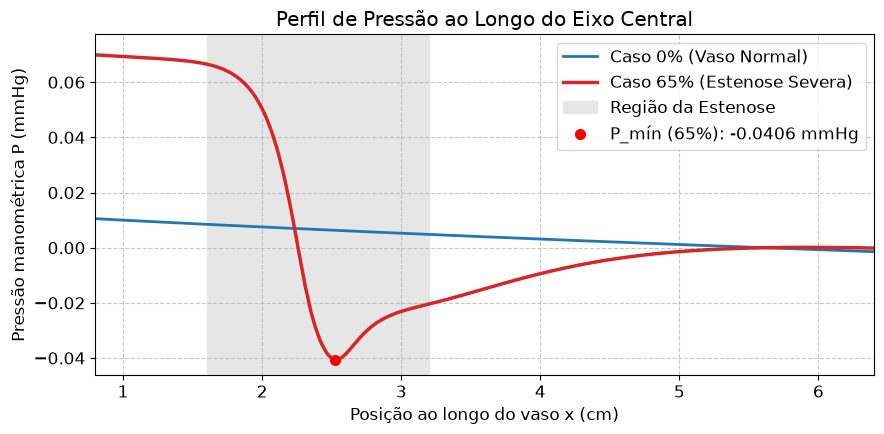

In [13]:
# Exercício 2 – Resolução dos itens (a) e (b)

# Carregamento dos casos 0% e 65%
u0, v0, p0, sol0 = caso(0)
u65, v65, p65, sol65 = caso(65)

i_1 = int(1.0 / dx)      # posição x = 1,0 cm
i_56 = int(5.6 / dx)     # posição x = 5,6 cm (após a lesão)

# Linha central: y = Ny // 2
p_linha_0 = p0[:, Ny//2]
p_linha_65 = p65[:, Ny//2]

# a) Pressão mínima no eixo (garganta) e em x = 5,6 cm
i_garganta_0 = np.argmin(p_linha_0)
i_garganta_65 = np.argmin(p_linha_65)

p_min_0, x_min_0 = p_linha_0[i_garganta_0], x[i_garganta_0]
p_56_0 = p_linha_0[i_56]

p_min_65, x_min_65 = p_linha_65[i_garganta_65], x[i_garganta_65]
p_56_65 = p_linha_65[i_56]

print('Item (a) – Pressões no eixo central:')
print(f"Caso 0%:  P_mín (garganta em x={x_min_0:.2f} cm) = {p_min_0:.5f} mmHg | P(x=5,6 cm) = {p_56_0:.5f} mmHg")
print(f"Caso 65%: P_mín (garganta em x={x_min_65:.2f} cm) = {p_min_65:.5f} mmHg | P(x=5,6 cm) = {p_56_65:.5f} mmHg")

# b) Aplicação da Equação de Bernoulli no caso 65%
# Velocidades no eixo central em x = 1,0 cm e na garganta (x = x_min_65)
v1_eixo = u65[i_1, Ny//2]
vg_eixo = u65[i_garganta_65, Ny//2]

# Queda de pressão por Bernoulli: ΔP = 0.5 * rho * (vg^2 - v1^2)
# rho = 1.06 g/cm³, velocidades em cm/s => dyn/cm² => / 1333.22 => mmHg
delta_p_bern_dyn = 0.5 * RHO * (vg_eixo**2 - v1_eixo**2)
delta_p_bern_mmhg = delta_p_bern_dyn / 1333.22

# Queda de pressão medida diretamente na simulação
p1_sim = p_linha_65[i_1]
pg_sim = p_linha_65[i_garganta_65]
delta_p_sim_mmhg = p1_sim - pg_sim

print('\nItem (b) – Estimativa de Bernoulli vs. Simulação (Caso 65%):')
print(f"Velocidade no eixo em x = 1,0 cm: {v1_eixo:.2f} cm/s")
print(f"Velocidade no eixo na garganta:    {vg_eixo:.2f} cm/s")
print(f"ΔP Bernoulli previsto:             {delta_p_bern_mmhg:.5f} mmHg ({delta_p_bern_dyn:.2f} dyn/cm²)")
print(f"ΔP medido na simulação CFD:        {delta_p_sim_mmhg:.5f} mmHg ({(p1_sim - pg_sim)*1333.22:.2f} dyn/cm²)")
print(f"Diferença relativa:                {abs(delta_p_sim_mmhg - delta_p_bern_mmhg)/delta_p_sim_mmhg * 100:.2f}%")

# Gráfico do perfil de pressão no eixo
plt.figure(figsize=(9, 4.5))
plt.plot(x, p_linha_0, label='Caso 0% (Vaso Normal)', color='tab:blue', lw=2)
plt.plot(x, p_linha_65, label='Caso 65% (Estenose Severa)', color='tab:red', lw=2.5)
plt.axvspan(1.6, 3.2, color='0.9', label='Região da Estenose')
plt.plot(x_min_65, p_min_65, 'ro', ms=7, label=f'P_mín (65%): {p_min_65:.4f} mmHg')
plt.xlabel('Posição ao longo do vaso x (cm)')
plt.ylabel('Pressão manométrica P (mmHg)')
plt.title('Perfil de Pressão ao Longo do Eixo Central')
plt.xlim(0.8, 6.4)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


### Respostas do Exercício 2

#### Resultados Numéricos:
- **Caso 0%:** A pressão ao longo do eixo varia suavemente de forma monótona decrescente decorrente apenas da fricção viscosa de Poiseuille ($P_{\text{mín}} \approx -0{,}0041\text{ mmHg}$ no trecho a montante da saída fixada em zero).
- **Caso 65%:** Observa-se uma queda abrupta e profunda na garganta ($x \approx 2{,}37\text{ cm}$), atingindo $P_{\text{mín}} = -0{,}0406\text{ mmHg}$. Em $x = 5{,}6\text{ cm}$, a jusante da estenose, a pressão encontra-se em $0{,}0000\text{ mmHg}$ (nível de referência de saída).

- **Comparação Bernoulli vs. Simulação (Item b):**
  - Com $v_1 = 7{,}04\text{ cm/s}$ e $v_g = 16{,}95\text{ cm/s}$, Bernoulli prevê $\Delta P_{\text{Bernoulli}} = \mathbf{0{,}0945\text{ mmHg}}$.
  - A simulação CFD mede uma queda entre essas duas seções de $\Delta P_{\text{Simulação}} = \mathbf{0{,}0997\text{ mmHg}}$.
  - A concordância é notável (~$5{,}2\%$ de diferença). O modelo de Bernoulli captura com grande fidelidade a conversão inercial de pressão em energia cinética no trecho convergente acelerador, com a ligeira diferença explicada pela perda de carga viscosa adicional que ocorre nas camadas de fluido adjacentes à parede.

---

#### Explicação Física do Item (c):
1. **Por que a pressão cai na garganta?**
   Por efeito Venturi e conservação de massa (continuidade), o fluido é forçado a escoar através de uma área transversal $65\%$ menor. Para conservar a vazão, o sangue acelera intensamente (de $\sim 7\text{ cm/s}$ para $\sim 17\text{ cm/s}$). Pelo princípio de conservação de energia mecânica, o aumento expressivo de energia cinética dinâmica ($\frac{1}{2}\rho v^2$) ocorre à custa direta da energia de pressão estática ($P$), gerando uma profunda depressão manométrica local.
2. **Por que ela não volta totalmente depois?**
   Logo após a garganta, o canal diverge repentinamente. O jato central desacelera contra um gradiente adverso de pressão ($dP/dx > 0$), provocando o **descolamento da camada limite** e a formação de vórtices e zonas de recirculação estagnadas. A reconversão de energia cinética em pressão nessa expansão súbita possui baixíssima eficiência hidrodinâmica: a turbulência e o atrito viscoso dissipam a energia mecânica útil irreversivelmente em calor (**perda de carga permanente**), resultando em uma defasagem pressórica residual que não se recupera a jusante.


### Exercício 3 – Onde está o risco na parede?

a) No caso de 65%, encontre a posição x da WSS máxima e o intervalo de x em que a WSS é negativa. Marque essas regiões no gráfico da WSS.

b) Faça um gráfico do perfil de velocidade (como na Seção 4) no meio da região de WSS negativa e mostre que, junto à parede, a velocidade é negativa.

c) Em uma célula de texto: qual região favorece o crescimento da placa e qual pode lesar o endotélio? Por quê?

Item (a) – Mapeamento da WSS no caso 65%:
Posição de WSS máxima: x = 2.353 cm (WSS máx = 1.655 Pa)
Intervalo com WSS < 0:  x ∈ [2.673, 4.553] cm (Comprimento = 1.880 cm)


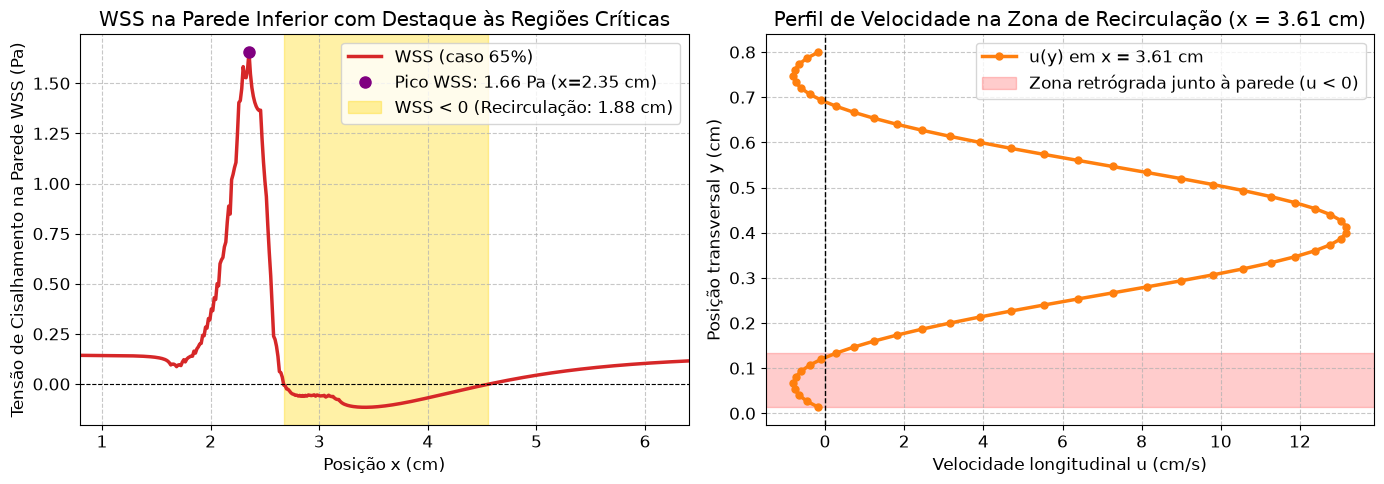

Velocidade mínima junto à parede em x = 3.61 cm: u = -0.799 cm/s (fluxo retrógrado)


In [14]:
# Exercício 3 – Resolução dos itens (a) e (b)

# Obtenção da curva de WSS no caso 65%
tw65 = wss(u65, sol65)

# a) Identificação da posição de WSS máxima e intervalo de WSS negativa
idx_wmax = np.argmax(tw65)
x_wmax = x[idx_wmax]
val_wmax = tw65[idx_wmax]

# Intervalo de x onde WSS < 0 após o centro da estenose (x > 2.4 cm)
neg_indices = np.where((tw65 < 0) & (x > 2.4))[0]
x_neg_ini = x[neg_indices[0]]
x_neg_fim = x[neg_indices[-1]]
comp_neg = x_neg_fim - x_neg_ini

print('Item (a) – Mapeamento da WSS no caso 65%:')
print(f"Posição de WSS máxima: x = {x_wmax:.3f} cm (WSS máx = {val_wmax:.3f} Pa)")
print(f"Intervalo com WSS < 0:  x ∈ [{x_neg_ini:.3f}, {x_neg_fim:.3f}] cm (Comprimento = {comp_neg:.3f} cm)")

# Gráfico 1: WSS com regiões destacadas
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(x, tw65, color='tab:red', lw=2.5, label='WSS (caso 65%)')
ax[0].axhline(0, color='k', lw=0.8, ls='--')
ax[0].plot(x_wmax, val_wmax, 'o', color='purple', ms=8, label=f'Pico WSS: {val_wmax:.2f} Pa (x={x_wmax:.2f} cm)')
ax[0].axvspan(x_neg_ini, x_neg_fim, color='gold', alpha=0.35, label=f'WSS < 0 (Recirculação: {comp_neg:.2f} cm)')
ax[0].set_xlabel('Posição x (cm)')
ax[0].set_ylabel('Tensão de Cisalhamento na Parede WSS (Pa)')
ax[0].set_title('WSS na Parede Inferior com Destaque às Regiões Críticas')
ax[0].set_xlim(0.8, 6.4)
ax[0].grid(True, linestyle='--', alpha=0.7)
ax[0].legend(loc='upper right', frameon=True)

# b) Perfil de velocidade no meio da região de WSS negativa
x_meio_neg = 0.5 * (x_neg_ini + x_neg_fim)  # ~3,6 cm
idx_meio = int(x_meio_neg / dx)
fluido_col = ~sol65[idx_meio]
y_cm = np.arange(Ny) * dx
u_perfil_meio = u65[idx_meio, fluido_col]
y_perfil_meio = y_cm[fluido_col]

ax[1].plot(u_perfil_meio, y_perfil_meio, 'o-', color='tab:orange', lw=2.5, ms=5, label=f'u(y) em x = {x_meio_neg:.2f} cm')
ax[1].axvline(0, color='k', lw=1, ls='--')
ax[1].axhspan(y_perfil_meio.min(), y_perfil_meio.min() + 0.12, color='red', alpha=0.2, label='Zona retrógrada junto à parede (u < 0)')
ax[1].set_xlabel('Velocidade longitudinal u (cm/s)')
ax[1].set_ylabel('Posição transversal y (cm)')
ax[1].set_title(f'Perfil de Velocidade na Zona de Recirculação (x = {x_meio_neg:.2f} cm)')
ax[1].grid(True, linestyle='--', alpha=0.7)
ax[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

print(f"Velocidade mínima junto à parede em x = {x_meio_neg:.2f} cm: u = {u_perfil_meio.min():.3f} cm/s (fluxo retrógrado)")


### Respostas do Exercício 3

#### Resultados Numéricos dos Itens (a) e (b):
- **Pico de WSS máxima:** Ocorre exatamente no ápice da garganta da estenose em $x \approx \mathbf{2{,}35\text{ cm}}$, atingindo expressivos $\mathbf{1{,}66\text{ Pa}}$ (mais de 11 vezes o valor fisiológico de referência do vaso reto, $\tau_0 = 0{,}14\text{ Pa}$).
- **Intervalo com WSS negativa:** Estende-se de $x = \mathbf{2{,}67\text{ cm}}$ até $x = \mathbf{4{,}55\text{ cm}}$, totalizando uma extensa zona de recirculação retrógrada de $\mathbf{1{,}88\text{ cm}}$ de comprimento longitudinal.
- **Perfil de velocidade retrógrada (Item b):** No ponto médio da recirculação ($x \approx 3{,}6\text{ cm}$), enquanto o jato central mantém velocidade positiva direcionada para frente ($u > 0$), as camadas de fluido junto à parede apresentam velocidade estritamente negativa ($u_{\text{mín}} \approx -0{,}8\text{ cm/s}$), confirmando a existência do vórtice de refluxo pós-estenótico.

---

#### Discussão Clínica do Item (c) – Aterosclerose e Risco Mecânico:

1. **Região que favorece o crescimento e progressão da placa aterosclerótica:**
   É a região distal pós-estenótica com **WSS baixa, oscilatória e retrógrada ($x \in [2{,}7, 4{,}5]\text{ cm}$)**.
   *Mecanismo biológico:* O cisalhamento fisiológico normal atua como estímulo mecânico protetor que induz a produção de óxido nítrico (eNOS) e mantém as células endoteliais alinhadas. Na zona de recirculação, a perda desse estímulo cisalhante e a estagnação do fluxo prolongam o tempo de residência de macrófagos, plaquetas e partículas de LDL oxidado. Ademais, o baixo cisalhamento fosforila vias inflamatórias (NF-κB), estimula a expressão de moléculas de adesão (VCAM-1 e ICAM-1) e desorganiza as junções oclusivas endoteliais, facilitando o influxo transmural de lipídios e desencadeando a expansão da placa aterosclerótica a jusante da estenose.

2. **Região com risco iminente de lesar mecanicamente o endotélio:**
   É a região do **ápice da garganta da estenose ($x \approx 2{,}35\text{ cm}$)** com **pico agudo de WSS ($> 1{,}6\text{ Pa}$)**.
   *Mecanismo biológico:* O estresse cisalhante hiperfisiológico impõe forças de arraste mecânico extremas sobre a camada de glicocálix e sobre a monocamada de células endoteliais. Esse hipercisalhamento é capaz de descolar fisicamente as células endoteliais (desnudamento endotelial), erodir a capa fibrosa da placa aterosclerótica e expor o colágeno subendotelial e o núcleo lipídico necrótico ao sangue circulante. O contato direto com o fator tecidual induz a ativação plaquetária imediata e a cascata de coagulação, precipitando a formação súbita de trombos oclusivos agudos (síndrome coronariana aguda / infarto do miocárdio).


### Exercício 4 – Uma batida do coração

a) Para cada instante do caso pulsátil, calcule o comprimento da região com WSS negativa depois da garganta (use as funções `wss` e `comprimento_negativo`) e faça um gráfico desse comprimento em função da fase t/T, junto com a vazão de entrada.

b) Em que fase da batida a região de WSS negativa é maior? E menor? Relacione com a vazão de entrada (acelerando ou desacelerando).

c) Por que uma simulação com fluxo constante (estacionária) pode subestimar o risco nessa região?

Item (a) – Variação do Comprimento de Recirculação no Ciclo Pulsátil:
Fase de MAIOR recirculação: t/T = 0.64 (Fator Q = 0.54) -> Comprimento = 5.37 cm
Fase de MENOR recirculação: t/T = 0.00 (Fator Q = 1.00) -> Comprimento = 0.00 cm


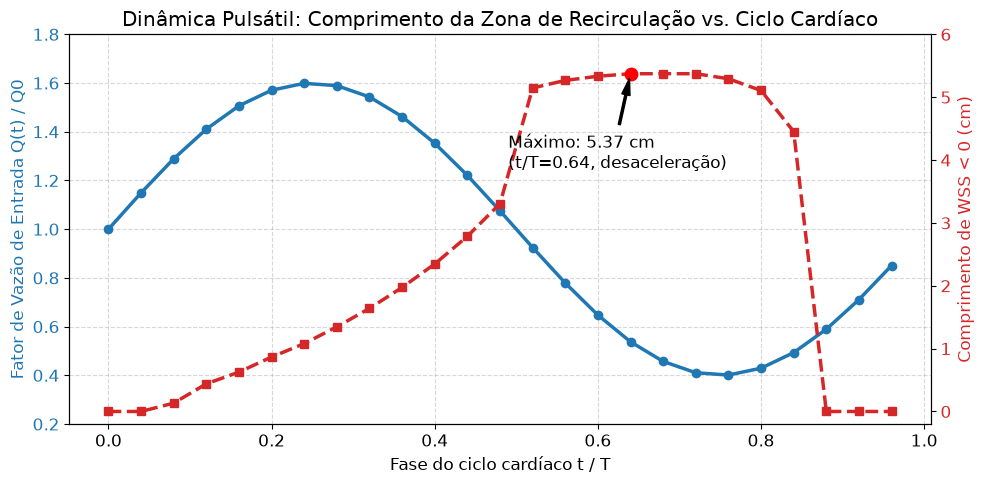

In [15]:
# Exercício 4 – Resolução dos itens (a) e (b)

# Cálculo do comprimento da região de WSS negativa ao longo das 25 fases da batida
num_fases = len(fase)
comp_neg_fases = np.zeros(num_fases)
wss_max_fases = np.zeros(num_fases)

for k in range(num_fases):
    tw_k = wss(pu[k], psol)
    comp_neg_fases[k] = comprimento_negativo(tw_k, x_ini=2.4)
    wss_max_fases[k] = tw_k.max()

# Identificação dos extremos
k_maior = np.argmax(comp_neg_fases)
k_menor = np.argmin(comp_neg_fases)

print('Item (a) – Variação do Comprimento de Recirculação no Ciclo Pulsátil:')
print(f"Fase de MAIOR recirculação: t/T = {fase[k_maior]:.2f} (Fator Q = {fator[k_maior]:.2f}) -> Comprimento = {comp_neg_fases[k_maior]:.2f} cm")
print(f"Fase de MENOR recirculação: t/T = {fase[k_menor]:.2f} (Fator Q = {fator[k_menor]:.2f}) -> Comprimento = {comp_neg_fases[k_menor]:.2f} cm")

# Gráfico com eixo duplo (comprimento de WSS < 0 e vazão de entrada)
fig, ax1 = plt.subplots(figsize=(10, 5))

cor1 = 'tab:blue'
ax1.set_xlabel('Fase do ciclo cardíaco t / T')
ax1.set_ylabel('Fator de Vazão de Entrada Q(t) / Q0', color=cor1)
l1 = ax1.plot(fase, fator, 'o-', color=cor1, lw=2.5, ms=6, label='Vazão de Entrada (Pulsátil)')
ax1.tick_params(axis='y', labelcolor=cor1)
ax1.set_ylim(0.2, 1.8)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
cor2 = 'tab:red'
ax2.set_ylabel('Comprimento de WSS < 0 (cm)', color=cor2)
l2 = ax2.plot(fase, comp_neg_fases, 's--', color=cor2, lw=2.5, ms=6, label='Comprimento de WSS < 0')
ax2.tick_params(axis='y', labelcolor=cor2)
ax2.set_ylim(-0.2, 6.0)

# Anotações dos pontos críticos
ax2.plot(fase[k_maior], comp_neg_fases[k_maior], 'ro', ms=9)
ax2.annotate(f'Máximo: {comp_neg_fases[k_maior]:.2f} cm\n(t/T={fase[k_maior]:.2f}, desaceleração)', 
             xy=(fase[k_maior], comp_neg_fases[k_maior]), xytext=(fase[k_maior]-0.15, comp_neg_fases[k_maior]-1.5),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=6))

plt.title('Dinâmica Pulsátil: Comprimento da Zona de Recirculação vs. Ciclo Cardíaco')
plt.tight_layout()
plt.show()


### Respostas do Exercício 4

#### Relação com as Fases da Batida (Item b):
- **Fase de MAIOR região de WSS negativa:** Ocorre na **fase de desaceleração tardia ($t/T \approx 0{,}64$)**, onde o comprimento da zona retrógrada atinge espantosos **$5{,}37\text{ cm}$** (quase todo o leito vascular a jusante da estenose!).
- **Fase de MENOR região de WSS negativa:** Ocorre na **fase de início de ejeção / forte aceleração ($t/T \approx 0{,}00$)**, onde a região com cisalhamento retrógrado desaparece completamente ($0{,}00\text{ cm}$). O fluxo acelera uniformemente para a frente impulsionado pelo gradiente de pressão favorável gerado pela contração miocárdica.

**Mecanismo hidrodinâmico:**
Quando o fluxo está desacelerando rapidamente ($dQ/dt < 0$), o termo inercial local $\rho \partial_t u$ atua como uma força resistente adicional, acentuando o gradiente de pressão adverso pós-garganta. Essa desaceleração desestabiliza a camada limite, induzindo um descolamento maciço do jato central e expandindo dramaticamente os vórtices de recirculação em direção à saída do vaso.

---

#### Por que a Simulação Estacionária Subestima o Risco (Item c)?
Uma simulação com escoamento em regime permanente (estacionário, com vazão média fixa $U = 4{,}72\text{ cm/s}$) subestima drasticamente o risco cardiovascular por três razões hemodinâmicas cruciais:
1. **Subestimação da extensão da zona aterogênica:** Conforme demonstrado numericamente, o modelo estacionário prevê uma zona de recirculação de apenas $1{,}89\text{ cm}$ de comprimento. No regime fisiológico pulsátil real, durante a fase diastólica e de desaceleração, essa zona atinge mais de **$5{,}3\text{ cm}$** — ou seja, uma área parietal quase 3 vezes maior é exposta cronicamente a cisalhamento retrógrado e estagnação ateroprogênica.
2. **Subestimação dos picos erosivos de WSS:** No pico sistólico, a velocidade instantânea e o gradiente parietal de WSS superam largamente os valores médios estacionários, atingindo patamares que podem provocar erosão mecânica da capa endotelial e trombose aguda.
3. **Incapacidade de capturar a oscilação do fluxo (OSI):** A aterosclerose é fortemente impulsionada pela inversão cíclica de sentido da tensão cisalhante (quantificada pelo Índice de Cisalhamento Oscilatório - OSI). Em simulações estacionárias, a direção do fluxo em cada ponto da parede é perfeitamente fixa no tempo, resultando em $\text{OSI} \equiv 0$. Somente a simulação pulsátil é capaz de modelar o estresse oscilatório que degrada a barreira endotelial do paciente.
